**Q3. Optimization-Based Efficient Frontier Construction**

(a) Annualized Stats

In [ ]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize
import matplotlib.pyplot as plt

df = pd.read_csv('crsp_sample.csv')
df['date'] = pd.to_datetime(df['date'])
df = df[(df['date'] >= '2022-01-01') & (df['date'] <= '2023-12-31')]

permnos = [39731, 79089, 83148]
df = df[df['permno'].isin(permnos)]

returns = df.pivot(index='date', columns='permno', values='ret')
returns = returns.dropna()
returns = returns[permnos]

mean_annual = returns.mean()*252
cov_annual = returns.cov()*252
std_annual = np.sqrt(np.diag(cov_annual))
corr_annual = returns.corr()

print("\nAnnualized Mean:\n", mean_annual)
print("\nAnnualized Std Dev:\n", std_annual)
print("\nAnnualized Covariance:\n", cov_annual)
print("\nAnnualized Correlation:\n", cov_annual)


Annualized Mean:
 permno
39731   -0.102641
79089   -0.626013
83148    0.207042
dtype: float64

Annualized Std Dev:
 [0.71821993 0.82308831 0.97234965]

Annualized Covariance:
 permno     39731     79089     83148
permno                              
39731   0.515840  0.094047  0.045145
79089   0.094047  0.677474  0.100449
83148   0.045145  0.100449  0.945464

Annualized Correlation:
 permno     39731     79089     83148
permno                              
39731   0.515840  0.094047  0.045145
79089   0.094047  0.677474  0.100449
83148   0.045145  0.100449  0.945464


(b) Formulate and solve the Mean-Variance Optimization Problem

In [ ]:
def portfolio_variance(weights, cov_matrix):
    return weights.T @ cov_matrix @ weights

def portfolio_return(weights, mean_returns):
    return weights.T @ mean_returns

#constraints
def get_constraints(target_return, mean_returns):
    cons = (
        {'type': 'eq', 'fun': lambda w: np.sum(w) - 1},  # sum of weights = 1
        {'type': 'eq', 'fun': lambda w: portfolio_return(w, mean_returns) - target_return}  # target return
    )
    return cons

#optimize
mu_min = min(mean_annual)
mu_max = max(mean_annual)
target_returns = np.arange(mu_min, mu_max + 0.0001, 0.005)
print(f"Number of target returns to optimize: {len(target_returns)}")

n_assets = len(mean_annual)
optimized_weights = []
optimized_returns = []
optimized_vols = []
optimized_sharpe = []

# initial guess (equal weight)
x0 = np.ones(n_assets)/n_assets

for mu_p in target_returns:
    cons = get_constraints(mu_p, mean_annual)
    bounds = tuple((0, 1) for _ in range(n_assets))  # no short selling
    result = minimize(portfolio_variance, x0, args=(cov_annual,),
                      method='SLSQP', bounds=bounds, constraints=cons)

    if result.success: #record the values
        w_opt = result.x
        ret = portfolio_return(w_opt, mean_annual)
        vol = np.sqrt(portfolio_variance(w_opt, cov_annual))
        sharpe = ret / vol  # risk-free = 0

        optimized_weights.append(w_opt)
        optimized_returns.append(ret)
        optimized_vols.append(vol)
        optimized_sharpe.append(sharpe)
    else:
        print("Optimization failed for target return:", mu_p)

Number of target returns to optimize: 167


(c) Visualize the Efficient Frontier and (d) Find the Tangency Portfolio (Maximum Sharpe Ratio)

In [ ]:
#use (d) to graph (c)
optimized_weights = np.array(optimized_weights)
optimized_returns = np.array(optimized_returns)
optimized_vols = np.array(optimized_vols)
optimized_sharpe = np.array(optimized_sharpe)

max_idx = np.argmax(optimized_sharpe)
tangent_weights = optimized_weights[max_idx]
tangent_return = optimized_returns[max_idx]
tangent_vol = optimized_vols[max_idx]
max_sharpe = optimized_sharpe[max_idx]

print("Tangency Portfolio (Max Sharpe):")
print("Weights:", np.round(tangent_weights,3))
print("Return:", round(tangent_return,3))
print("Standard Deviation:", round(tangent_vol,3))
print("Sharpe:", round(max_sharpe,3))

Tangency Portfolio (Max Sharpe):
Weights: [0.01 0.   0.99]
Return: 0.204
Standard Deviation: 0.963
Sharpe: 0.212


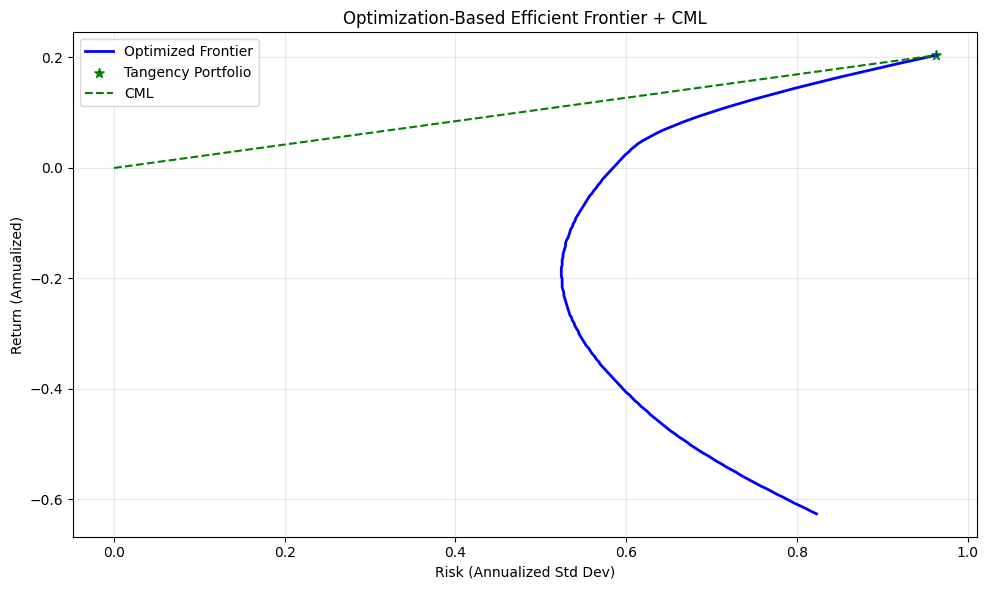

In [ ]:
plt.figure(figsize=(10,6))
plt.plot(np.round(optimized_vols,3), np.round(optimized_returns,3), 'b-', linewidth=2, label='Optimized Frontier')
plt.scatter(np.round(tangent_vol,3), np.round(tangent_return,3), color='green', s=50, marker='*', label='Tangency Portfolio')

# cml
x = np.linspace(0, max(optimized_vols), 100)
y = max_sharpe * x
plt.plot(x, y, 'g--', label='CML')

plt.xlabel("Risk (Annualized Std Dev)")
plt.ylabel("Return (Annualized)")
plt.title("Optimization-Based Efficient Frontier + CML")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

(e) Comparison (Brute Force vs. Optimized)

**Accuracy:** Comparing the optimal weights, mean, standard deviation, and the Sharpe obtained by the two methods shows that they are both accurate, only differing by approximately a thousandth to a hundredth.

Brute-force method:

Optimal weights: [0. 0. 1.]

Return: 0.207

Standard Deviation: 0.972

Sharpe: 0.213,

Optimized:

Optimal weights: [0.01 0.   0.99]

Return: 0.204

Standard Deviation: 0.963

Sharpe: 0.212

**Efficiency and Computational Cost (Time Complexity):**

In [ ]:
import math

n_assets = 3 # assets
step_size = 0.01 # grid step for brute-force
m_targets = 167 # number of target returns for optimization computed in (b)

# brute force #portfolios
num_values_per_weight = int(1/step_size) + 1

# use stars-and-bars formula: C(N + n - 1, n-1)
num_portfolios = math.comb(num_values_per_weight + n_assets - 1, n_assets - 1)

# assume each portfolio takes ~O(n^2) operations for variance
brute_force_ops = num_portfolios * n_assets**2

print(f"Brute-force estimated portfolios: {num_portfolios}")
print(f"Brute-force estimated operations: {brute_force_ops}")

#estimate #operations for optimized version
# each quadratic program ~ O(n^3), 167 times
optimization_ops = m_targets * n_assets**3
print(f"Optimization estimated operations: {optimization_ops}")

#compare
speedup = brute_force_ops / optimization_ops
print(f"Estimated efficiency gain (Brute-force / Optimization): {speedup:.1f}x")

Brute-force estimated portfolios: 5253
Brute-force estimated operations: 47277
Optimization estimated operations: 4509
Estimated efficiency gain (Brute-force / Optimization): 10.5x


Using a step size of 0.005, the optimized approach solves 167 target returns, compared to the 5253 estimated portfolios processed by the brute-force method. The total number of operations for the optimized approach is 4509 compared to 47277 for brute force, making it around 10.5 times faster. The optimized version is significantly more efficient and costs less computationally.